# Лабораторная работа №1. Регрессия

Датасет Wine Quality (UCI): красное и белое вино вместе. Задача — предсказать оценку `quality` по физико-химическим признакам. Основная метрика — RMSE (порог < 0.70), дополнительная — MAE.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter("ignore")

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, FunctionTransformer, SplineTransformer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

sns.set(style="whitegrid")
RANDOM_STATE = 42

## 1. Знакомство с данными

In [ ]:
red = pd.read_csv("winequality-red.csv", sep=";")
white = pd.read_csv("winequality-white.csv", sep=";")

# объединяем в один датасет, тип вина сохраняем как признак
red["is_red"] = 1
white["is_red"] = 0
data = pd.concat([red, white], ignore_index=True)

print("красных:", len(red), "белых:", len(white), "всего:", len(data))
print("пропусков:", data.isna().sum().sum())
print("полных дубликатов строк:", data.duplicated().sum())

# удаляем дубликаты ДО разбиения
data = data.drop_duplicates().reset_index(drop=True)
print("после удаления дубликатов:", len(data), "| красных:", (data["is_red"] == 1).sum(), "белых:", (data["is_red"] == 0).sum())
data.head()

красных: 1599 белых: 4898 всего: 6497
пропусков: 0
полных дубликатов строк: 1177
после удаления дубликатов: 5320 | красных: 1359 белых: 3961


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,1


In [3]:
stats = data.describe().T[["mean", "std", "min", "50%", "max"]]
stats["skew"] = data.skew()
stats.round(3)

,mean,std,min,50%,max,skew
fixed acidity,7.215,1.320,3.800,7.000,15.900,1.650
volatile acidity,0.344,0.168,0.080,0.300,1.580,1.505
citric acid,0.318,0.147,0.000,0.310,1.660,0.484
residual sugar,5.048,4.500,0.600,2.700,65.800,1.707
chlorides,0.057,0.037,0.009,0.047,0.611,5.338
free sulfur dioxide,30.037,17.805,1.000,28.000,289.000,1.363
total sulfur dioxide,114.109,56.774,6.000,116.000,440.000,0.064
density,0.995,0.003,0.987,0.995,1.039,0.666
pH,3.225,0.160,2.720,3.210,4.010,0.390
sulphates,0.533,0.150,0.220,0.510,2.000,1.809


- Пропусков нет. Масштабы признаков совсем разные (density ≈ 0.99, total sulfur dioxide доходит до 440), поэтому линейной модели нужно масштабирование. Многие признаки скошены.

{3: 30, 4: 206, 5: 1752, 6: 2323, 7: 856, 8: 148, 9: 5}
средняя оценка: красное 5.62 | белое 5.85


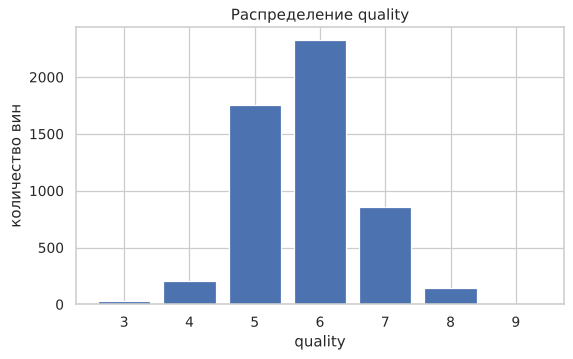

In [4]:
counts = data["quality"].value_counts().sort_index()
plt.figure(figsize=(7, 4))
plt.bar(counts.index, counts.values)
plt.xlabel("quality")
plt.ylabel("количество вин")
plt.title("Распределение quality")
plt.show()

print(counts.to_dict())
print("средняя оценка: красное", round(data.loc[data["is_red"] == 1, "quality"].mean(), 2),
      "| белое", round(data.loc[data["is_red"] == 0, "quality"].mean(), 2))

- Оценки 5 и 6 составляют 77% данных, оценок 3 и 9 всего 35 штук.   
Это дисбаланс, поэтому крайние оценки модель будет предсказывать плохо, при разбиении нужна стратификация.

corr(density, alcohol) = -0.67
corr(density, residual sugar) = 0.52


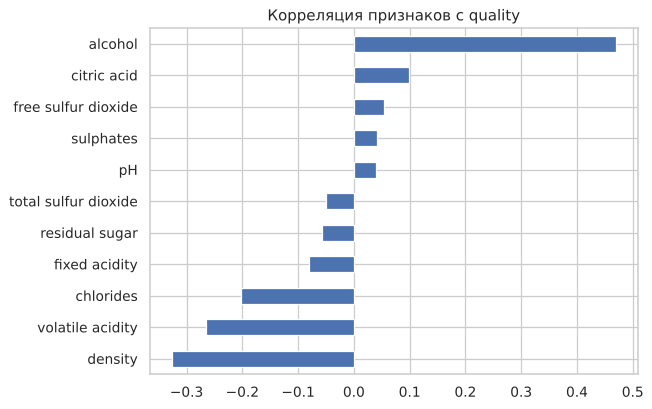

,все,красное,белое
alcohol,0.47,0.48,0.46
density,-0.33,-0.18,-0.34
volatile acidity,-0.27,-0.40,-0.19
chlorides,-0.20,-0.13,-0.22
citric acid,0.10,0.23,0.01
fixed acidity,-0.08,0.12,-0.12
residual sugar,-0.06,0.01,-0.12
free sulfur dioxide,0.05,-0.05,0.01
total sulfur dioxide,-0.05,-0.18,-0.18
sulphates,0.04,0.25,0.05


In [5]:
corr = pd.DataFrame({
    "все": data.corr()["quality"],
    "красное": data[data["is_red"] == 1].corr()["quality"],
    "белое": data[data["is_red"] == 0].corr()["quality"],
}).drop(["quality", "is_red"])
corr = corr.reindex(corr["все"].abs().sort_values(ascending=False).index)

corr["все"].sort_values().plot(kind="barh", figsize=(7, 5), title="Корреляция признаков с quality")
plt.show()

print("corr(density, alcohol) =", round(data["density"].corr(data["alcohol"]), 2))
print("corr(density, residual sugar) =", round(data["density"].corr(data["residual sugar"]), 2))
corr.round(2)

- `alcohol` (+0.47) — самая сильная связь: чем крепче вино, тем выше оценка.
- `density` (−0.33), `volatile acidity` (−0.27), `chlorides` (−0.20) — связь отрицательная (уксусный и солёный привкус снижают оценку).
- `density` почти определяется спиртом и сахаром (корреляция −0.67 и 0.52) → мультиколлинеарность, коэффициенты линейной модели при этих признаках будут неустойчивыми.
- У красного и белого вина зависимости разные: у красного важны `volatile acidity`, `sulphates`, `citric acid`, у белого — `density`, `chlorides`. Одна линейная модель это плохо учитывает.
- Почти нулевая корреляция не значит, что признак бесполезен: связь может быть нелинейной.

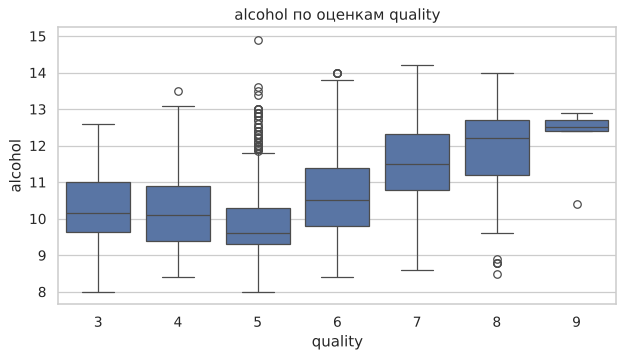

In [6]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=data, x="quality", y="alcohol")
plt.title("alcohol по оценкам quality")
plt.show()

- для оценок 3–5 спирт почти одинаковый, рост начинается с 6, значит зависимость нелинейная.
- Оценки сильно перекрываются по признакам → идеально предсказать quality не получится.

## 2. Разбиение на train и test

In [ ]:
X = data.drop(columns="quality")
y = data["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("train:", X_train.shape, "test:", X_test.shape)

# проверка на утечку
train_rows = set(map(tuple, pd.concat([X_train, y_train], axis=1).values))
in_train = [tuple(r) in train_rows for r in pd.concat([X_test, y_test], axis=1).values]
print(f"строк теста, которые есть в train: {sum(in_train)} ({np.mean(in_train):.1%})")

# кросс-валидация на train — по ней подбираю параметры и выбираю модель
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate(y_true, y_pred):
    return {"RMSE": root_mean_squared_error(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred)}

results = {}

train: (4256, 12) test: (1064, 12)
строк теста, которые есть в train: 0 (0.0%)


- **Размер:** 80/20 — 4256 вин в train, 1064 в test. Большая часть данных идёт на обучение, а тысячи объектов достаточно для стабильной оценки.
- **Способ:** случайное разбиение со стратификацией по `quality`, чтобы редкие оценки попали в обе части в той же пропорции. `random_state=42` — для воспроизводимости.
- После удаления дубликатов ни одна строка теста не совпадает со строкой train — утечки нет.
- **Тест** используется один раз в конце. Параметры и лучшая модель выбираются по 5-фолдовой кросс-валидации на train.
- **Почему нельзя много раз смотреть на тест:** если выбирать модель по тесту, решение подгоняется под эти конкретные объекты, оценка становится завышенной, и на новых данных результат будет хуже.

## 3. Baseline

In [8]:
const = y_train.mean()
print("константа (среднее по train):", round(const, 3))

results["Baseline"] = evaluate(y_test, np.full(len(y_test), const))
results["Baseline"]

константа (среднее по train): 5.795


{'RMSE': 0.8801023384558065, 'MAE': 0.694789576149019}

- Для RMSE лучшая константа — среднее (минимизирует сумму квадратов отклонений). Считаю его только по train.
- Baseline: RMSE 0.880. Модель, которая не лучше этого числа, ничего полезного из признаков не извлекает.

## 4. Метрики
- **MAE** — средняя абсолютная ошибка: на сколько баллов в среднем ошибается модель.
- **RMSE** — корень из среднего квадрата ошибки, тоже в баллах (сильнее реагирует на большие ошибки, тк они возводятся в квадрат).

## 5. Модели
### Линейная регрессия

In [9]:
lin_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

cv_rmse = -cross_val_score(lin_reg, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
print("CV RMSE:", cv_rmse.mean().round(4))

lin_reg.fit(X_train, y_train)
print("train RMSE:", round(root_mean_squared_error(y_train, lin_reg.predict(X_train)), 4))
results["Linear Regression"] = evaluate(y_test, lin_reg.predict(X_test))
results["Linear Regression"]

CV RMSE: 0.7327
train RMSE: 0.7307


{'RMSE': 0.7292420437086437, 'MAE': 0.5660009475168251}

In [10]:
# коэффициенты без масштабирования и после StandardScaler
lr_raw = LinearRegression().fit(X_train, y_train)

coefs = pd.DataFrame({
    "без масштабирования": lr_raw.coef_,
    "со StandardScaler": lin_reg.named_steps["model"].coef_,
}, index=X.columns)
coefs.sort_values("со StandardScaler", key=abs, ascending=False).round(4)

,без масштабирования,со StandardScaler
density,-94.7183,-0.2810
alcohol,0.2314,0.2755
residual sugar,0.0510,0.2268
volatile acidity,-1.3258,-0.2209
sulphates,0.8040,0.1174
is_red,0.2604,0.1137
free sulfur dioxide,0.0063,0.1118
pH,0.6656,0.1067
total sulfur dioxide,-0.0019,-0.1054
fixed acidity,0.0731,0.0973


- RMSE 0.729 — лучше baseline, но **порог 0.70 не пройден**. Ошибки на train и test почти равны (0.731 и 0.729) → модель не переобучается, а недообучается: зависимости нелинейные и разные для красного и белого вина.
- **Масштабирование:** без него самый большой коэффициент у `density` (−94.7), но это потому, что density меняется в тысячных — изменение на 1 нереально. У `total sulfur dioxide` наоборот почти ноль (−0.002), потому что он меняется на десятки. Сравнивать такие коэффициенты нельзя. После `StandardScaler` коэффициент = изменение прогноза при изменении признака на 1 std, и их можно сравнивать. На качество обычной регрессии масштабирование не влияет.
- **Самые влиятельные признаки:** `density` (−0.28), `alcohol` (+0.28), `residual sugar` (+0.23), `volatile acidity` (−0.22). `alcohol` и `volatile acidity` совпадают с EDA. Большой вес `residual sugar` (при почти нулевой корреляции с quality) — следствие мультиколлинеарности с `density`: модель компенсирует один признак другим, поэтому их веса нельзя трактовать по отдельности.

### Улучшенная линейная регрессия

In [ ]:
# логарифмирую скошенные признаки, добавляю полиномиальные признаки 2 степени,
# а затем раскладываю каждый из них сплайнами (кусочные многочлены) 
skewed = ["fixed acidity", "volatile acidity", "residual sugar", "chlorides",
          "free sulfur dioxide", "total sulfur dioxide", "sulphates"]

def log_transform(X):
    X = X.copy()
    X[skewed] = np.log1p(X[skewed])
    return X

poly_reg = Pipeline([
    ("log", FunctionTransformer(log_transform)),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("spline", SplineTransformer(n_knots=7, degree=3)),
    ("model", Ridge()),
])

# признаков очень много, поэтому Ridge; alpha подбираю по CV
poly_search = GridSearchCV(poly_reg, param_grid={"model__alpha": [1, 3, 10, 30]},
                           cv=cv, scoring="neg_root_mean_squared_error")
poly_search.fit(X_train, y_train)
print("лучший alpha:", poly_search.best_params_["model__alpha"])
print("CV RMSE:", round(-poly_search.best_score_, 4))

poly_reg = poly_search.best_estimator_
n_feat = poly_reg[:-1].transform(X_train.head(1)).shape[1]
print("признаков после преобразований:", n_feat)
print("train RMSE:", round(root_mean_squared_error(y_train, poly_reg.predict(X_train)), 4))
results["Linear Regression (log + poly2 + splines + Ridge)"] = evaluate(y_test, poly_reg.predict(X_test))
results["Linear Regression (log + poly2 + splines + Ridge)"]

лучший alpha: 10
CV RMSE: 0.6968
признаков после преобразований: 810
train RMSE: 0.669


{'RMSE': 0.6886205235482612, 'MAE': 0.5320835078928742}

- `log1p` уменьшает влияние выбросов в скошенных признаках.
- Полиномиальные признаки (квадраты и попарные произведения) дают взаимодействия признаков, например произведения с `is_red` — разные зависимости для красного и белого вина.
- Сплайны раскладывают каждый признак на кусочные многочлены, поэтому модель может описать изогнутую зависимость (как у `alcohol`). Модель при этом остаётся линейной: прогноз — взвешенная сумма признаков.
- Признаков становится 810 → без регуляризации модель переобучится, поэтому `Ridge` (L2). На исходных 12 признаках регуляризация ничего не дала бы, тк проблема в недообучении.
- **Результат: RMSE 0.689 — порог пройден**, CV тоже улучшилась (0.733 → 0.697). Запас небольшой: линейная модель на этих данных близка к своему пределу.
- Коэффициенты этой модели не интерпретирую: 810 сильно связанных между собой признаков, отдельный вес ничего не значит. Поэтому важность признаков для линейной регрессии смотрю по обычной модели выше.

### Random Forest

In [12]:
rf_search = GridSearchCV(
    RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    param_grid={"max_features": [0.33, 0.5, 1.0], "min_samples_leaf": [1, 3, 5]},
    cv=cv, scoring="neg_root_mean_squared_error"
)
rf_search.fit(X_train, y_train)
print("лучшие параметры:", rf_search.best_params_)
print("CV RMSE:", round(-rf_search.best_score_, 4))

rf = rf_search.best_estimator_
print("train RMSE:", round(root_mean_squared_error(y_train, rf.predict(X_train)), 4))
results["Random Forest"] = evaluate(y_test, rf.predict(X_test))
results["Random Forest"]

лучшие параметры: {'max_features': 0.33, 'min_samples_leaf': 1}
CV RMSE: 0.6869
train RMSE: 0.2521


{'RMSE': 0.6798080178276488, 'MAE': 0.5256109022556391}

- RMSE 0.680, MAE 0.526 — лучше линейной регрессии.
- train RMSE 0.25 сильно ниже CV (0.69): лес почти запоминает обучающие данные, это нормально для глубоких деревьев. Обобщающую способность показывают CV и тест, они близки.

### Gradient Boosting

In [13]:
gb_search = GridSearchCV(
    GradientBoostingRegressor(learning_rate=0.05, subsample=0.8, random_state=RANDOM_STATE),
    param_grid={"max_depth": [3, 5, 7], "n_estimators": [200, 400]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1
)
gb_search.fit(X_train, y_train)
print("лучшие параметры:", gb_search.best_params_)
print("CV RMSE:", round(-gb_search.best_score_, 4))

gb = gb_search.best_estimator_
print("train RMSE:", round(root_mean_squared_error(y_train, gb.predict(X_train)), 4))
results["Gradient Boosting"] = evaluate(y_test, gb.predict(X_test))
results["Gradient Boosting"]

лучшие параметры: {'max_depth': 5, 'n_estimators': 200}
CV RMSE: 0.6964
train RMSE: 0.5087


{'RMSE': 0.6896016531264328, 'MAE': 0.5293626725999041}

- RMSE 0.690, MAE 0.529 — почти как у леса.
- Лучшие параметры — глубина 5 и 200 деревьев. train RMSE 0.51 против 0.70 на CV: бустинг тоже подстраивается под train, но меньше, чем лес.

## 6. Сравнение моделей

In [14]:
results_table = pd.DataFrame(results).T.round(4)
results_table

,RMSE,MAE
Baseline,0.8801,0.6948
Linear Regression,0.7292,0.5660
Linear Regression (log + poly2 + splines + Ridge),0.6886,0.5321
Random Forest,0.6798,0.5256
Gradient Boosting,0.6896,0.5294


- **Все модели лучше baseline и проходят порог 0.70** (обычная линейная регрессия — нет, улучшенная — да).
- **Лучшая модель — Random Forest** (RMSE 0.680). Выбрана по CV на train (не по тесту). Разница между тремя моделями небольшая.
- **Обычная линейная регрессия хуже всех:** предполагает линейное и одинаковое для всех вин влияние признаков, а в данных зависимости нелинейные и разные для красного и белого. Преобразования признаков это частично исправляют.
- **Деревья** сами находят нелинейности и взаимодействия, без ручных преобразований.
- **Лес немного лучше бустинга:** целевая переменная шумная (субъективная оценка экспертов), а лес усредняет много независимых деревьев и хорошо сглаживает шум.

## 7. Feature importance

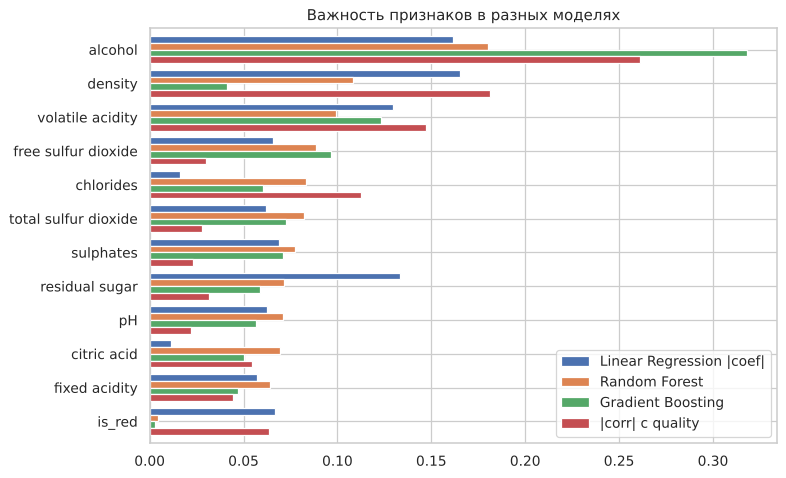

,Linear Regression |coef|,Random Forest,Gradient Boosting,|corr| с quality
alcohol,0.162,0.180,0.318,0.261
density,0.165,0.108,0.041,0.181
volatile acidity,0.130,0.099,0.123,0.147
free sulfur dioxide,0.066,0.089,0.097,0.030
chlorides,0.016,0.083,0.060,0.112
total sulfur dioxide,0.062,0.082,0.073,0.028
sulphates,0.069,0.078,0.071,0.023
residual sugar,0.133,0.071,0.059,0.032
pH,0.063,0.071,0.057,0.022
citric acid,0.011,0.069,0.050,0.054


In [15]:
# модуль коэффициентов LR и корреляцию нормирую, чтобы во всех столбцах сумма была 1
importance = pd.DataFrame({
    "Linear Regression |coef|": coefs["со StandardScaler"].abs(),
    "Random Forest": pd.Series(rf.feature_importances_, index=X.columns),
    "Gradient Boosting": pd.Series(gb.feature_importances_, index=X.columns),
    "|corr| с quality": data.corr()["quality"].drop("quality").abs(),
})
importance = (importance / importance.sum()).sort_values("Random Forest", ascending=False)

importance.plot(kind="barh", figsize=(9, 6), width=0.8)
plt.gca().invert_yaxis()
plt.title("Важность признаков в разных моделях")
plt.show()
importance.round(3)

- **Главный признак** — `alcohol` важнее всего везде, `volatile acidity` в топ-3, всё сходится с EDA.
- GB почти не использует `density`: её информация уже есть в `alcohol`.
- **Отличия от EDA:** `free sulfur dioxide` почти не коррелирует с quality, но у деревьев на 3–4 месте → связь нелинейная (плохо и слишком мало, и слишком много SO₂).
- **Отличия от линейной регрессии:** у неё в топе `density` и `residual sugar` — эффект мультиколлинеарности, у деревьев `residual sugar` в середине.
- `is_red` деревьям почти не нужен: тип вина и так определяется по составу.
- О причинности говорить нельзя: Importance показывает только полезность признака для модели и связь в этих данных. Данные наблюдательные: может, хороший виноград даёт и больше спирта, и лучший вкус. Для вывода о причинности нужен эксперимент.

## 8. Анализ ошибок (Random Forest)

средняя ошибка: -0.022 | std: 0.68
доля ошибок больше 1 балла: 0.119


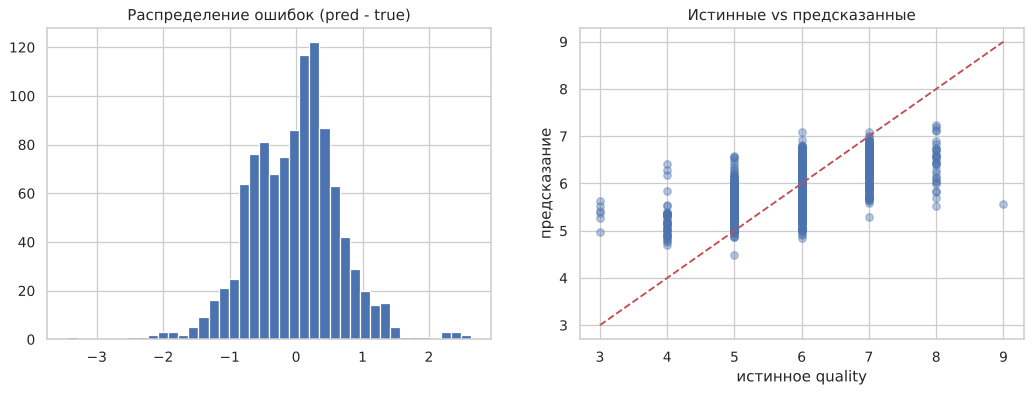

In [16]:
pred = rf.predict(X_test)
errors = pd.DataFrame({"true": y_test, "pred": pred})
errors["error"] = errors["pred"] - errors["true"]
errors["abs_error"] = errors["error"].abs()
print("средняя ошибка:", round(errors["error"].mean(), 3), "| std:", round(errors["error"].std(), 3))
print("доля ошибок больше 1 балла:", round((errors["abs_error"] > 1).mean(), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(errors["error"], bins=40)
axes[0].set_title("Распределение ошибок (pred - true)")
axes[1].scatter(errors["true"], errors["pred"], alpha=0.4)
axes[1].plot([3, 9], [3, 9], "r--")
axes[1].set_xlabel("истинное quality")
axes[1].set_ylabel("предсказание")
axes[1].set_title("Истинные vs предсказанные")
plt.show()

In [17]:
# качество по каждому значению quality
by_quality = errors.groupby("true").agg(
    n=("error", "size"),
    mean_pred=("pred", "mean"),
    mean_error=("error", "mean"),
    MAE=("abs_error", "mean"),
)
by_quality["n_train"] = y_train.value_counts()
by_quality.round(3)

,n,mean_pred,mean_error,MAE,n_train
true,,,,,
3,6,5.368,2.368,2.368,24
4,41,5.230,1.230,1.230,165
5,350,5.426,0.426,0.433,1402
6,465,5.841,-0.159,0.386,1858
7,171,6.335,-0.665,0.666,685
8,30,6.450,-1.550,1.550,118
9,1,5.557,-3.443,3.443,4


- Ошибки почти не смещены (средняя −0.02), большинство в пределах ±1, но 12% ошибок больше 1 балла, есть хвосты до −3.4 и +2.6.
- Прогнозы «сжаты» к центру: для 3–4 модель предсказывает ~5.2–5.4, для 8 — ~6.5.
- Модель хорошо работает на частых оценках 5–6 (MAE 0.39–0.43) и плохо на редких: 3 и 4 завышает на 2.4 и 1.2, 8 занижает на 1.6, единственное вино с оценкой 9 — на 3.4.

In [ ]:
worst = errors.sort_values("abs_error", ascending=False).head(6)  # самые большие ошибки
pd.concat([worst[["true", "pred"]].round(2), X_test.loc[worst.index]], axis=1)

,true,pred,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,is_red
2012,9,5.56,9.1,0.27,0.45,10.60,0.035,28.0,124.0,0.9970,3.20,0.46,10.4,0
1982,3,5.63,6.9,0.39,0.40,4.60,0.022,5.0,19.0,0.9915,3.31,0.37,12.6,0
1571,3,5.53,8.5,0.26,0.21,16.20,0.074,41.0,197.0,0.9980,3.02,0.50,9.8,0
2549,8,5.52,8.2,0.22,0.36,6.80,0.034,12.0,90.0,0.9944,3.01,0.38,10.5,0
2783,3,5.42,6.7,0.25,0.26,1.55,0.041,118.5,216.0,0.9949,3.55,0.63,9.4,0
4984,4,6.41,5.8,0.26,0.30,2.60,0.034,75.0,129.0,0.9902,3.20,0.38,11.5,0


In [19]:
# медианы признаков по оценкам (train) для сравнения
X_train.assign(quality=y_train).groupby("quality")[
    ["alcohol", "volatile acidity", "chlorides", "free sulfur dioxide", "total sulfur dioxide"]
].median()

,alcohol,volatile acidity,chlorides,free sulfur dioxide,total sulfur dioxide
quality,,,,,
3,10.45,0.46,0.054,17.0,102.5
4,10.10,0.38,0.050,15.0,103.0
5,9.60,0.34,0.053,26.0,124.5
6,10.50,0.27,0.046,29.0,116.0
7,11.50,0.28,0.039,29.0,111.0
8,12.20,0.29,0.037,31.5,111.0
9,12.60,0.31,0.026,29.0,116.0


**Разбор сильных ошибок:**
- **2012 (белое, 9 → 5.6):** `alcohol` 10.4 при медиане 12.6 для оценки 9, остальное обычное. По составу вино ничем не выделяется — высокая оценка связана с тем, чего нет в данных (аромат, сорт). К тому же вин с оценкой 9 в train всего 4.
- **1982 (белое, 3 → 5.6):** крепкое (12.6%) и с низкими хлоридами — похоже на хорошее вино. Но очень мало SO₂ (5 и 19 при обычных ~30 и ~115) — возможно, вино испортилось. Такое сочетание редкое.
- **2783 (белое, 3 → 5.4):** наоборот, очень много свободного SO₂ (118.5) — вероятный дефект (запах серы), таких примеров в train мало.
- **4984 (белое, 4 → 6.4):** по всем признакам типичное хорошее вино (11.5% спирта, низкая летучая кислотность) — скорее всего, шум в оценке экспертов.

**Почему редкие оценки предсказываются хуже:**
1. Мало примеров (24 вина с оценкой 3 и 4 с оценкой 9 против 1858 шестёрок) — на общую ошибку они почти не влияют.
2. Лес усредняет оценки похожих вин, а похожие на редкие — в основном 5–7, поэтому прогноз тянется к середине.
3. Оценки перекрываются по признакам, а сама оценка экспертов субъективна.

## Итоги
- Дубликаты удалены до разбиения, чтобы не было утечки между train и test.
- Главные признаки: `alcohol` (+), `volatile acidity` (−), `density` (−). Зависимости у красного и белого вина различаются.
- Все модели лучше baseline (0.880) и проходят порог 0.70. Обычная линейная регрессия (0.729) — нет, после `log` + полиномов + сплайнов + `Ridge` — да (0.689).
- Лучшая модель — **Random Forest: RMSE 0.680, MAE 0.526**. Ансамбли деревьев выигрывают за счёт нелинейностей и взаимодействий признаков.
- Модель хорошо предсказывает оценки 5–7 и плохо — редкие крайние (3, 4, 8, 9), прогнозы смещаются к середине.